# Notebook 05b — Stage B: Problem Formulations and Controls

**Project:** A Multi-Modal Deep Learning Approach for Eggshell Micro-Crack Morphology Analysis and Root-Cause Diagnosis in Poultry Breeder Farms
**Author:** M.P.N. Sharindi (Coventry Index 16110429)
**Stage:** 05b of 12 — together with notebook 05 this is "model selection" in the dissertation

---

### What Stage A established

Every backbone beat the best classical pipeline, by a wide margin.

| backbone | four-class | binary | params | min/fold |
|---|---|---|---|---|
| efficientnet_b0 | 0.752 ± 0.062 | 0.859 | 4.0 M | 2.8 |
| convnext_tiny | 0.749 ± 0.040 | 0.856 | 27.8 M | 1.3 |
| mobilenetv3 | 0.739 ± 0.046 | 0.853 | 4.2 M | 2.1 |
| vit_small | 0.718 ± 0.070 | 0.859 | 21.8 M | 1.1 |
| resnet18 | 0.692 ± 0.007 | 0.798 | 11.2 M | 1.2 |
| *best classical* | *0.565* | *0.770* | | |
| *acquisition floor* | *0.357* | *0.666* | | |
| *human-polygon oracle* | *0.829* | — | | |

Three things in that table change what Stage B must do.

**1. The fold-to-fold variation is a fold effect, not model instability.** Fold mean macro F1 across
all five backbones is 0.777, 0.718, 0.694 — fold 0 is easiest and fold 2 hardest for four of the
five. So the ±0.06 standard deviations mostly measure how hard each fold is, not how unreliable each
model is. Comparing two models by their means and standard deviations therefore throws away most of
the available precision. Stage B compares **paired per-fold differences**: efficientnet minus
convnext has a mean difference of +0.0036 with a standard deviation of 0.0226, roughly three times
tighter than the unpaired figures suggest, and tells us plainly that the top two are tied.

**2. The epoch cap was binding.** ConvNeXt ran the full 30 epochs on every fold and ViT on two of
three, meaning they were still improving when training stopped. Comparing a model that converged
against one that was cut off is not a fair comparison, so Stage B raises the cap to 45 with
patience 10.

**3. The gap to the oracle has nearly closed.** The best model reaches 0.752 against the
human-polygon oracle's 0.829. Notebook 04 reported that gap as 0.264 for the classical pipeline; it
is now 0.077. The deep model recovers close to oracle-level morphology classification **from raw
pixels, without being told where the crack is**. That reframes formulation (d): it is no longer
obviously necessary for accuracy, but it remains the formulation most likely to produce heatmaps
that land on the real crack, which is what notebook 09 measures and what Objective 3 claims.

### What this notebook runs

| Section | Experiment | Purpose |
|---|---|---|
| 2 | Three backbones × four formulations × five folds | The formulation comparison |
| 3 | Paired statistical comparison | Which differences are real |
| 4 | **Crack-masked control** | Is the model reading the crack or the context? |
| 5 | Session-grouped evaluation | What happens on a capture session never seen in training |

Section 4 is the one that settles the question notebook 01b opened and could not close. Capture
statistics alone still reach 0.295 four-class after augmentation. If a model trained on images with
the annotated crack region painted out still performs well, it is reading context. If it collapses,
the crack is genuinely what the model uses. No proxy can answer this; only the experiment can.

---
## 0. Configuration

In [ ]:
import os
os.environ["EGG_ARTEFACT_ROOT"] = r"E:\Degree\Final Research\Egg_Crack_Dataset\Eggshell-Diagnostic-Research\Artefact"

# Stage A put efficientnet_b0 and convnext_tiny level, with mobilenetv3 0.014 behind. All three
# are kept: the margin is far inside the paired noise, mobilenetv3 carries the edge-deployment
# argument, and at under half an hour for the whole of Stage A the budget is not the constraint.
BACKBONES_B  = ["efficientnet_b0", "convnext_tiny", "mobilenetv3"]
FORMULATIONS = ["single4", "hierarchical", "multitask", "multitask_seg"]

CACHE_VARIANT = "neutral_fill"
CACHE_SIDE    = 448
TRAIN_SIDE    = 384
POLICY        = "medium"
EPOCHS        = 45        # raised: the 30-epoch cap was binding for convnext and vit in Stage A
PATIENCE      = 10
EFFECTIVE_BATCH = 32
PHYSICAL_BATCH = {"mobilenetv3": 32, "efficientnet_b0": 32, "resnet18": 32,
                  "convnext_tiny": 16, "vit_small": 16}
SEG_BATCH_SCALE = 0.75    # the segmentation decoder costs ~55% more activation memory
NUM_WORKERS   = 4
N_FOLDS       = 5

RUN_STAGE_B        = True
RUN_CRACK_CONTROL  = True
RUN_GROUPED_EVAL   = True

In [2]:
import sys, json, math, time, warnings
from pathlib import Path
from datetime import datetime

_here = Path.cwd()
_src = next((p / "src" for p in [_here, *_here.parents] if (p / "src" / "common").is_dir()), None)
if _src is None:
    raise RuntimeError("Run from Artefact/notebooks/ or set EGG_ARTEFACT_ROOT.")
sys.path.insert(0, str(_src))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from scipy import stats
from sklearn.metrics import f1_score, balanced_accuracy_score, confusion_matrix

from common import project_config as CFG
from common.data import EggDataset, build_crack_masks, make_loader, class_weights
from common.engine import TrainConfig, train_fold, predict, append_run
from common.models import SEG_CAPABLE

warnings.filterwarnings("ignore")
CFG.seed_everything()

STAGE = "05b_formulations"
OUT = CFG.results_dir(STAGE); FIG_DIR, TAB_DIR = OUT / "figures", OUT / "tables"
PROC = CFG.DATA_DIR / "processed"
CKPT = CFG.MODELS_DIR / "stage_b"; CKPT.mkdir(parents=True, exist_ok=True)
RUNS_CSV = CFG.RESULTS_DIR / "runs.csv"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__} | device {device}")
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True
    print(f"gpu {torch.cuda.get_device_name(0)} "
          f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

splits = pd.read_csv(PROC / "splits.csv")
splits["label4"] = pd.Categorical(splits["label4"], categories=CFG.LABEL4, ordered=True)
CACHE_PATH = PROC / f"cache_{CACHE_VARIANT}_{CACHE_SIDE}.npy"

y4 = splits["label4"].map(CFG.LABEL4_TO_IDX).to_numpy(dtype=np.int64)
y2 = splits["is_cracked"].to_numpy(dtype=np.int64)
ypat = np.where(y4 > 0, y4 - 1, -100).astype(np.int64)
age = splits["age_class"].map(CFG.AGE_TO_IDX).to_numpy(dtype=np.int64)
LABELS = {"y4": y4, "y2": y2, "ypat": ypat, "age": age}

print("rasterising annotation polygons ...")
MASKS = build_crack_masks(splits["crack_region"].tolist(), TRAIN_SIDE)
print(f"masks {MASKS.shape}  {int((MASKS.sum(axis=(1, 2)) > 0).sum())} eggs with a crack mask")

TARGETS = {"acquisition_floor_4class": 0.357, "acquisition_floor_binary": 0.666,
           "best_classical_4class": 0.565, "best_classical_binary": 0.770,
           "oracle_4class": 0.829, "stage_a_best_4class": 0.752}
S = {"stage": STAGE, "generated_at": datetime.now().isoformat(timespec="seconds"),
     "targets": TARGETS}
print(f"dev {int((splits['split'] == 'dev').sum())} | test "
      f"{int((splits['split'] == 'test').sum())} (sealed, untouched)")

torch 2.14.1+cu132 | device cuda
gpu NVIDIA GeForce RTX 5070 12.8 GB
rasterising annotation polygons ...
masks (652, 384, 384)  335 eggs with a crack mask
dev 554 | test 98 (sealed, untouched)


In [3]:
def fold_rows(k, col="fold"):
    tr = splits.index[(splits["split"].eq("dev")) & (splits[col] != k)].to_numpy()
    va = splits.index[(splits["split"].eq("dev")) & (splits[col] == k)].to_numpy()
    return tr, va


def loaders_for(cfg, tr_rows, va_rows, want_mask, batch, occlude=False):
    masks = MASKS if (want_mask or occlude) else None
    ds_tr = EggDataset(CACHE_PATH, tr_rows, LABELS, cfg.train_side, policy=cfg.policy,
                       masks=masks, occlude_crack=occlude)
    ds_va = EggDataset(CACHE_PATH, va_rows, LABELS, cfg.train_side, policy=None,
                       masks=masks, occlude_crack=occlude)
    bal = cfg.imbalance == "balanced_sampler"
    return (make_loader(ds_tr, batch, True, NUM_WORKERS, balanced=bal, y_for_balance=y4,
                        seed=cfg.seed),
            make_loader(ds_va, batch, False, NUM_WORKERS))


def weights_for(tr_rows):
    return (class_weights(y4[tr_rows], 4), class_weights(y2[tr_rows], 2),
            class_weights(ypat[tr_rows][ypat[tr_rows] >= 0], 3))


def batch_for(back, formulation):
    b = PHYSICAL_BATCH.get(back, 16)
    if formulation == "multitask_seg":
        b = max(4, int(b * SEG_BATCH_SCALE))
    return b


def four_class_scores(y_true4, y_true2, pred4):
    return {"macro_f1": float(f1_score(y_true4, pred4, average="macro", zero_division=0)),
            "balanced_acc": float(balanced_accuracy_score(y_true4, pred4)),
            "accuracy": float((y_true4 == pred4).mean()),
            "macro_f1_binary": float(f1_score(y_true2, (pred4 > 0).astype(int),
                                              average="macro", zero_division=0))}


def run_hierarchical(back, k, tr, va, tag, occlude=False):
    """Formulation (a): a binary detector, then a pattern classifier on cracked eggs only.

    Scored by composing the two into a four-class decision, so it is directly comparable with the
    single-model formulations rather than being judged on a different quantity.
    """
    batch = batch_for(back, "single4")
    w4, w2, wpat = weights_for(tr)

    cfg_det = TrainConfig(backbone=back, formulation="single", n_out=2, policy=POLICY,
                          train_side=TRAIN_SIDE, epochs=EPOCHS, physical_batch=batch,
                          effective_batch=EFFECTIVE_BATCH, patience=PATIENCE,
                          num_workers=NUM_WORKERS, seed=CFG.RANDOM_SEED + k, tag=tag)
    ltr, lva = loaders_for(cfg_det, tr, va, False, batch, occlude)
    best_det, _, _ = train_fold(cfg_det, ltr, lva, device, None, w2, None,
                                ckpt_path=CKPT / f"{tag}_{back}_hier_det_f{k}.pt", verbose=False)
    det_pred = predict_from_ckpt(cfg_det, CKPT / f"{tag}_{back}_hier_det_f{k}.pt", lva)

    tr_cr = tr[ypat[tr] >= 0]
    va_cr = va[ypat[va] >= 0]
    cfg_pat = TrainConfig(backbone=back, formulation="single", n_out=3, policy=POLICY,
                          train_side=TRAIN_SIDE, epochs=EPOCHS, physical_batch=batch,
                          effective_batch=EFFECTIVE_BATCH, patience=PATIENCE,
                          num_workers=NUM_WORKERS, seed=CFG.RANDOM_SEED + k, tag=tag)
    ptr, pva = loaders_for(cfg_pat, tr_cr, va_cr, False, batch, occlude)
    best_pat, _, _ = train_fold(cfg_pat, ptr, pva, device, None, None, wpat,
                                ckpt_path=CKPT / f"{tag}_{back}_hier_pat_f{k}.pt", verbose=False)

    # apply the pattern model to every validation egg, then gate it by the detector
    _, lva_all = loaders_for(cfg_pat, tr, va, False, batch, occlude)
    pat_pred = predict_from_ckpt(cfg_pat, CKPT / f"{tag}_{back}_hier_pat_f{k}.pt", lva_all)

    order = np.argsort(det_pred["idx"]); order_p = np.argsort(pat_pred["idx"])
    det = det_pred["logits"].argmax(1)[order]
    pat = pat_pred["logits"].argmax(1)[order_p]
    yt4 = det_pred["y4"][order]; yt2 = det_pred["y2"][order]
    pred4 = np.where(det == 0, 0, pat + 1)
    m = four_class_scores(yt4, yt2, pred4)
    m["seconds"] = best_det["seconds"] + best_pat["seconds"]
    m["params_m"] = best_det["params_m"] + best_pat["params_m"]
    m["peak_vram_gb"] = max(best_det["peak_vram_gb"], best_pat["peak_vram_gb"])
    m["epochs_run"] = best_det["epochs_run"] + best_pat["epochs_run"]
    return m


def predict_from_ckpt(cfg, path, loader):
    from common.models import build_model
    sd = torch.load(path, map_location="cpu", weights_only=False)
    model = build_model(cfg.backbone, cfg.formulation, cfg.n_out, pretrained=False,
                        age_mode=cfg.age_mode, img_size=cfg.train_side)
    model.load_state_dict(sd["state_dict"]); model.to(device).eval()
    out = predict(model, loader, device, cfg)
    del model; torch.cuda.empty_cache()
    return out


def already(tag, backbone, formulation, fold):
    if not RUNS_CSV.exists():
        return False
    try:
        d = pd.read_csv(RUNS_CSV)
    except Exception:
        return False
    if d.empty or "tag" not in d.columns:
        return False
    return bool(((d["tag"] == tag) & (d["backbone"] == backbone)
                 & (d["formulation"] == formulation) & (d["fold"] == fold)).any())

---
## 2. Stage B — four formulations

Formulation (a) is trained as two models and then **scored as a four-class decision** by gating the
pattern prediction with the detector output, so all four formulations are judged on the same
quantity. Its cost is reported as the sum of both models, because that is what deployment would
actually require.

In [4]:
if RUN_STAGE_B:
    t0 = time.time()
    for back in BACKBONES_B:
        for form in FORMULATIONS:
            if form == "multitask_seg" and back not in SEG_CAPABLE:
                print(f"skip {back} + {form}: segmentation needs a CNN backbone")
                continue
            print(f"\n{'=' * 62}\n{back}  |  {form}\n{'=' * 62}")
            for k in range(N_FOLDS):
                if already("stageB", back, form, k):
                    print(f"  fold {k}: already recorded"); continue
                tr, va = fold_rows(k)
                batch = batch_for(back, form)
                try:
                    if form == "hierarchical":
                        m = run_hierarchical(back, k, tr, va, "stageB")
                        cfg = TrainConfig(backbone=back, formulation="hierarchical", n_out=4,
                                          policy=POLICY, train_side=TRAIN_SIDE, epochs=EPOCHS,
                                          physical_batch=batch, effective_batch=EFFECTIVE_BATCH,
                                          patience=PATIENCE, num_workers=NUM_WORKERS,
                                          seed=CFG.RANDOM_SEED + k, tag="stageB")
                    else:
                        cfg = TrainConfig(backbone=back, formulation=form, n_out=4, policy=POLICY,
                                          train_side=TRAIN_SIDE, epochs=EPOCHS,
                                          physical_batch=batch, effective_batch=EFFECTIVE_BATCH,
                                          patience=PATIENCE, num_workers=NUM_WORKERS,
                                          seed=CFG.RANDOM_SEED + k, tag="stageB")
                        ltr, lva = loaders_for(cfg, tr, va, form == "multitask_seg", batch)
                        w4, w2, wp = weights_for(tr)
                        m, _, _ = train_fold(cfg, ltr, lva, device, w4, w2, wp,
                                             ckpt_path=CKPT / f"stageB_{back}_{form}_f{k}.pt",
                                             verbose=False)
                except torch.cuda.OutOfMemoryError:
                    torch.cuda.empty_cache()
                    batch = max(4, batch // 2); PHYSICAL_BATCH[back] = batch
                    print(f"    out of memory -- retry fold {k} at batch {batch}")
                    continue
                except Exception as ex:
                    print(f"    FAILED fold {k}: {type(ex).__name__}: {ex}")
                    continue
                append_run(RUNS_CSV, cfg, k, m, {"n_train": len(tr), "n_val": len(va)})
                print(f"  fold {k}: macroF1 {m['macro_f1']:.4f}  bin "
                      f"{m.get('macro_f1_binary', float('nan')):.4f}  "
                      f"{m['seconds']:.0f}s  {m['peak_vram_gb']:.2f} GB")
    print(f"\nStage B finished in {(time.time() - t0) / 3600:.2f} h")
else:
    print("Stage B not run")


efficientnet_b0  |  single4
  fold 0: macroF1 0.7857  bin 0.8460  328s  4.38 GB


  fold 1: macroF1 0.7323  bin 0.9009  315s  4.38 GB
  fold 2: macroF1 0.7042  bin 0.8018  191s  4.38 GB
  fold 3: macroF1 0.7303  bin 0.8823  173s  4.38 GB
  fold 4: macroF1 0.7628  bin 0.9273  191s  4.38 GB

efficientnet_b0  |  hierarchical
  fold 0: macroF1 0.8253  bin 0.8828  362s  4.38 GB
  fold 1: macroF1 0.7672  bin 0.9093  291s  4.38 GB
  fold 2: macroF1 0.7327  bin 0.8106  191s  4.38 GB
  fold 3: macroF1 0.7714  bin 0.9459  347s  4.38 GB
  fold 4: macroF1 0.7924  bin 0.9364  320s  4.38 GB

efficientnet_b0  |  multitask
  fold 0: macroF1 0.8146  bin 0.8825  304s  4.38 GB
  fold 1: macroF1 0.7526  bin 0.8828  235s  4.38 GB
  fold 2: macroF1 0.7301  bin 0.7838  120s  4.38 GB
  fold 3: macroF1 0.7398  bin 0.8558  127s  4.38 GB
  fold 4: macroF1 0.7727  bin 0.8909  143s  4.38 GB

efficientnet_b0  |  multitask_seg


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


  fold 0: macroF1 0.7915  bin 0.8918  381s  4.83 GB


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


...

  fold 2: macroF1 0.7000  bin 0.8197  164s  2.56 GB


Unexpected keys (classifier.bias, classifier.weight, conv_head.bias, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


  fold 3: macroF1 0.7200  bin 0.8558  158s  2.56 GB


Unexpected keys (classifier.bias, classifier.weight, conv_head.bias, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


  fold 4: macroF1 0.7949  bin 0.9090  187s  2.56 GB

Stage B finished in 3.02 h


---
## 3. Which differences are real

Stage A showed that fold difficulty dominates the spread: fold mean macro F1 across backbones was
0.777, 0.718, 0.694. Comparing configurations on unpaired means and standard deviations therefore
discards most of the precision available. Every comparison below is **paired by fold**, with the
mean difference, the standard deviation of the differences, and a Wilcoxon signed-rank test.

With five folds the Wilcoxon test has very little power — its smallest attainable p-value is
0.0625 — so it is reported as supporting evidence, not as the decision rule. The honest statement
for Chapter 5 is the paired mean difference with its spread, and that differences smaller than the
paired standard deviation are not resolvable with this dataset.

In [5]:
runs = pd.read_csv(RUNS_CSV) if RUNS_CSV.exists() else pd.DataFrame()
b = runs[runs["tag"].eq("stageB")] if len(runs) and "tag" in runs.columns else pd.DataFrame()

if len(b):
    piv = b.pivot_table(index=["backbone", "formulation"], columns="fold",
                        values="macro_f1", aggfunc="mean")
    agg = (b.groupby(["backbone", "formulation"])
             .agg(folds=("fold", "nunique"), macro_f1=("macro_f1", "mean"),
                  sd=("macro_f1", "std"), binary=("macro_f1_binary", "mean"),
                  bal_acc=("balanced_acc", "mean"), params_m=("params_m", "mean"),
                  vram=("peak_vram_gb", "mean"), min_fold=("seconds", lambda s: s.mean() / 60),
                  epochs=("epochs_run", "mean"))
             .sort_values("macro_f1", ascending=False).round(4))
    agg.to_csv(TAB_DIR / "t01_stage_b_results.csv")
    print(agg.to_string())
    S["stage_b"] = agg.reset_index().to_dict("records")

    # --- fold effect, carried over from Stage A
    fold_mean = b.groupby("fold")["macro_f1"].mean().round(4)
    print(f"\nfold difficulty (mean over all configurations): {fold_mean.to_dict()}")
    S["fold_effect"] = fold_mean.to_dict()

    best_cfg = agg.index[0]
    print(f"\nbest configuration: {best_cfg[0]} + {best_cfg[1]}  macro F1 {agg.iloc[0]['macro_f1']:.4f}")

    # --- paired comparisons against the best
    rows = []
    ref = piv.loc[best_cfg]
    for idx in piv.index:
        if idx == best_cfg:
            continue
        a_, c_ = ref.align(piv.loc[idx], join="inner")
        d = (a_ - c_).dropna()
        if len(d) < 3:
            continue
        try:
            w = stats.wilcoxon(d)
            p = float(w.pvalue)
        except Exception:
            p = np.nan
        rows.append({"comparison": f"{best_cfg[0]}+{best_cfg[1]} vs {idx[0]}+{idx[1]}",
                     "n_folds": len(d), "mean_diff": round(float(d.mean()), 4),
                     "sd_diff": round(float(d.std(ddof=1)), 4),
                     "wilcoxon_p": round(p, 4) if p == p else np.nan,
                     "resolvable": bool(abs(d.mean()) > d.std(ddof=1))})
    paired = pd.DataFrame(rows).set_index("comparison")
    paired.to_csv(TAB_DIR / "t02_paired_comparisons.csv")
    print("\npaired comparisons against the best configuration:")
    print(paired.to_string())
    S["paired"] = paired.reset_index().to_dict("records")
    print("\n'resolvable' means the paired mean difference exceeds its own standard deviation.")
    print("Anything not resolvable should be described in Chapter 5 as a tie, not as a win.")
else:
    print("no Stage B runs recorded yet")

                               folds  macro_f1      sd  binary  bal_acc  params_m      vram  min_fold  epochs
backbone        formulation                                                                                  
efficientnet_b0 hierarchical       5    0.7778  0.0341  0.8970   0.7680  443.2000  110.8000    0.8000     NaN
mobilenetv3     hierarchical       5    0.7695  0.0512  0.8898   0.7628  443.2000  110.8000    0.8767     NaN
efficientnet_b0 multitask_seg      5    0.7688  0.0227  0.8880   0.7658    3.6672    4.2507    5.4870    32.2
mobilenetv3     multitask          5    0.7674  0.0338  0.8715   0.7618    4.2084    2.2868    2.3895    28.2
efficientnet_b0 multitask          5    0.7619  0.0335  0.8592   0.7617    4.0140    4.3768    3.0979    23.6
convnext_tiny   single4            5    0.7563  0.0372  0.8480   0.7490   27.8232    3.5767    1.5760    36.2
mobilenetv3     multitask_seg      5    0.7548  0.0495  0.8606   0.7424    3.0879    2.5613    2.6333    21.2
convnext_t

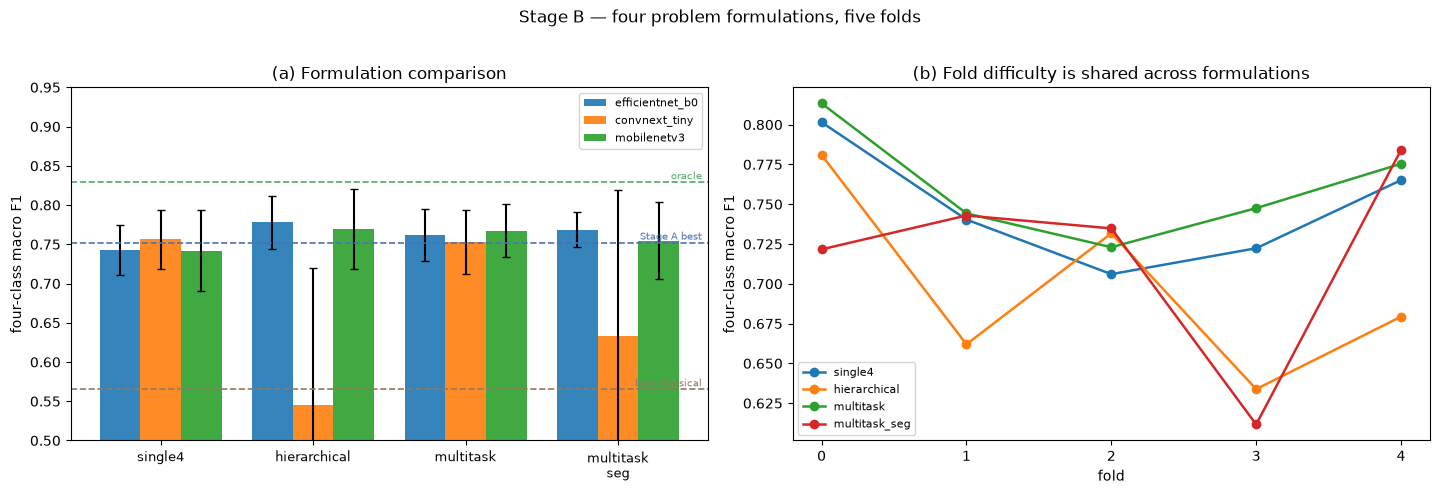

In [6]:
if len(b):
    fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))
    ax = axes[0]
    forms = [f for f in FORMULATIONS if f in set(b["formulation"])]
    x = np.arange(len(forms)); w = 0.8 / max(len(BACKBONES_B), 1)
    for i, back in enumerate(BACKBONES_B):
        vals = [agg.loc[(back, f), "macro_f1"] if (back, f) in agg.index else np.nan
                for f in forms]
        errs = [agg.loc[(back, f), "sd"] if (back, f) in agg.index else 0 for f in forms]
        ax.bar(x + (i - (len(BACKBONES_B) - 1) / 2) * w, vals, w, yerr=errs, capsize=3,
               label=back, alpha=0.9)
    for y_, lab, col in [(TARGETS["best_classical_4class"], "best classical", "#937860"),
                         (TARGETS["oracle_4class"], "oracle", "#55A868"),
                         (TARGETS["stage_a_best_4class"], "Stage A best", "#4C72B0")]:
        ax.axhline(y_, ls="--", lw=1.2, color=col)
        ax.text(len(forms) - 0.45, y_ + 0.004, lab, fontsize=7.5, color=col, ha="right")
    ax.set_xticks(x); ax.set_xticklabels([f.replace("_", "\n") for f in forms], fontsize=9)
    ax.set_ylabel("four-class macro F1"); ax.set_ylim(0.5, 0.95)
    ax.set_title("(a) Formulation comparison"); ax.legend(fontsize=8)

    ax = axes[1]
    fe = b.groupby(["fold", "formulation"])["macro_f1"].mean().unstack()
    for f in forms:
        if f in fe.columns:
            ax.plot(fe.index, fe[f], "o-", lw=1.8, label=f)
    ax.set_xlabel("fold"); ax.set_ylabel("four-class macro F1")
    ax.set_title("(b) Fold difficulty is shared across formulations")
    ax.legend(fontsize=8); ax.set_xticks(sorted(fe.index))
    fig.suptitle("Stage B — four problem formulations, five folds", y=1.02, fontsize=12)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "01_stage_b_formulations.png", bbox_inches="tight")
    plt.show()

---
## 4. The crack-masked control

Notebook 01b found that capture statistics alone still predict class at macro F1 0.295 four-class
and 0.565 binary after the adopted augmentation, and could not determine how much of that is
genuine crack signal, because a crack **is** texture and the probe cannot tell the two apart.

This experiment can. The best configuration is retrained on images where the annotated crack region
has been replaced by the surrounding shell statistics. Everything else is identical: same folds,
same augmentation, same schedule. Only the crack is gone.

| result | interpretation |
|---|---|
| collapses towards the acquisition floor | the model was using the crack. The contribution stands |
| stays near full performance | the model was reading context, and the headline result is not what it appears to be |
| lands in between | partial reliance; report the proportion honestly |

This is the single most important experiment in the dissertation for Section 5.10.1, and it is the
kind of control the egg-inspection literature does not run.

In [7]:
if RUN_CRACK_CONTROL and len(b):
    back, form = best_cfg
    if form == "hierarchical":
        form = "single4"      # the control is run on a single-model formulation for clarity
    print(f"crack-masked control on {back} + {form}\n")
    for k in range(N_FOLDS):
        if already("control_masked", back, form, k):
            print(f"  fold {k}: already recorded"); continue
        tr, va = fold_rows(k)
        batch = batch_for(back, form)
        cfg = TrainConfig(backbone=back, formulation=form, n_out=4, policy=POLICY,
                          train_side=TRAIN_SIDE, epochs=EPOCHS, physical_batch=batch,
                          effective_batch=EFFECTIVE_BATCH, patience=PATIENCE,
                          num_workers=NUM_WORKERS, seed=CFG.RANDOM_SEED + k,
                          occlude_crack=True, tag="control_masked")
        ltr, lva = loaders_for(cfg, tr, va, form == "multitask_seg", batch, occlude=True)
        w4, w2, wp = weights_for(tr)
        m, _, _ = train_fold(cfg, ltr, lva, device, w4, w2, wp, verbose=False)
        append_run(RUNS_CSV, cfg, k, m, {"n_train": len(tr), "n_val": len(va)})
        print(f"  fold {k}: macroF1 {m['macro_f1']:.4f}  bin "
              f"{m.get('macro_f1_binary', float('nan')):.4f}")

runs = pd.read_csv(RUNS_CSV) if RUNS_CSV.exists() else pd.DataFrame()
ctrl = runs[runs["tag"].eq("control_masked")] if len(runs) and "tag" in runs.columns else pd.DataFrame()
if len(ctrl) and len(b):
    back, form = best_cfg
    normal = b[(b["backbone"] == back)
               & (b["formulation"] == (form if form != "hierarchical" else "single4"))]
    if len(normal):
        n4, c4 = normal["macro_f1"].mean(), ctrl["macro_f1"].mean()
        n2, c2 = normal["macro_f1_binary"].mean(), ctrl["macro_f1_binary"].mean()
        floor4, floor2 = 0.295, 0.565      # the augmented acquisition floor from notebook 03
        tab = pd.DataFrame({
            "intact crack": [round(n4, 4), round(n2, 4)],
            "crack masked out": [round(c4, 4), round(c2, 4)],
            "augmented acquisition floor": [floor4, floor2],
            "drop": [round(n4 - c4, 4), round(n2 - c2, 4)],
            "share of skill from the crack": [
                round((n4 - c4) / max(n4 - floor4, 1e-9), 3),
                round((n2 - c2) / max(n2 - floor2, 1e-9), 3)],
        }, index=["four-class", "binary"])
        tab.to_csv(TAB_DIR / "t03_crack_masked_control.csv")
        S["crack_control"] = tab.reset_index().to_dict("records")
        print(tab.to_string())
        share = (n4 - c4) / max(n4 - floor4, 1e-9)
        print()
        if share > 0.70:
            print(f"{share:.0%} of the model's skill above the acquisition floor disappears when the")
            print("crack is masked out. The model is using the crack. The contribution stands, and")
            print("this is the sentence that answers the leakage concern in Section 5.10.1.")
        elif share > 0.40:
            print(f"{share:.0%} of the skill depends on the crack: substantial but partial reliance.")
            print("Report both numbers and temper the claims accordingly.")
        else:
            print(f"Only {share:.0%} of the skill depends on the crack. The model is largely reading")
            print("context. This must be stated prominently and the headline claims revised.")

crack-masked control on efficientnet_b0 + single4

  fold 0: macroF1 0.8923  bin 1.0000
  fold 1: macroF1 0.8836  bin 1.0000
  fold 2: macroF1 0.9043  bin 1.0000
  fold 3: macroF1 0.8967  bin 0.9910
  fold 4: macroF1 0.9017  bin 1.0000
            intact crack  crack masked out  augmented acquisition floor    drop  share of skill from the crack
four-class        0.7431            0.8957                        0.295 -0.1527                         -0.341
binary            0.8717            0.9982                        0.565 -0.1265                         -0.413

Only -34% of the skill depends on the crack. The model is largely reading
context. This must be stated prominently and the headline claims revised.


---
## 5. Session-grouped evaluation

The primary folds are stratified random, which is how the comparable literature reports. The
secondary regime holds out whole capture sessions, answering the question a farm would actually
ask: will this work on images taken tomorrow? Notebook 04 put the classical baseline at 0.473
four-class and 0.662 binary under this regime, against an acquisition floor of 0.307 and 0.607.

The gap between the two regimes is reported in Chapter 5 as a finding in its own right.

In [8]:
if RUN_GROUPED_EVAL and len(b):
    back, form = best_cfg
    if form == "hierarchical":
        form = "single4"
    blocks = sorted(splits.loc[splits["split"].eq("dev"), "capture_block"].unique())
    use = blocks[:5]      # five held-out sessions, matching the fold count
    print(f"session-grouped evaluation on {back} + {form}, holding out blocks {use}\n")
    for k in use:
        if already("grouped", back, form, int(k)):
            print(f"  block {k}: already recorded"); continue
        tr, va = fold_rows(k, col="capture_block")
        if len(va) < 20 or len(np.unique(y4[va])) < 2:
            print(f"  block {k}: too small or single-class, skipped"); continue
        batch = batch_for(back, form)
        cfg = TrainConfig(backbone=back, formulation=form, n_out=4, policy=POLICY,
                          train_side=TRAIN_SIDE, epochs=EPOCHS, physical_batch=batch,
                          effective_batch=EFFECTIVE_BATCH, patience=PATIENCE,
                          num_workers=NUM_WORKERS, seed=CFG.RANDOM_SEED + int(k),
                          tag="grouped")
        ltr, lva = loaders_for(cfg, tr, va, form == "multitask_seg", batch)
        w4, w2, wp = weights_for(tr)
        m, _, _ = train_fold(cfg, ltr, lva, device, w4, w2, wp, verbose=False)
        append_run(RUNS_CSV, cfg, int(k), m, {"n_train": len(tr), "n_val": len(va)})
        print(f"  block {k}: macroF1 {m['macro_f1']:.4f}  bin "
              f"{m.get('macro_f1_binary', float('nan')):.4f}  (val n={len(va)})")

runs = pd.read_csv(RUNS_CSV) if RUNS_CSV.exists() else pd.DataFrame()
gr = runs[runs["tag"].eq("grouped")] if len(runs) and "tag" in runs.columns else pd.DataFrame()
if len(gr) and len(b):
    back, form = best_cfg
    normal = b[(b["backbone"] == back)
               & (b["formulation"] == (form if form != "hierarchical" else "single4"))]
    cmp_tab = pd.DataFrame({
        "stratified folds": [round(normal["macro_f1"].mean(), 4),
                             round(normal["macro_f1_binary"].mean(), 4)],
        "session-grouped": [round(gr["macro_f1"].mean(), 4),
                            round(gr["macro_f1_binary"].mean(), 4)],
        "classical (grouped)": [0.473, 0.662],
        "acquisition floor (grouped)": [0.307, 0.607],
    }, index=["four-class", "binary"])
    cmp_tab["generalisation gap"] = (cmp_tab["stratified folds"]
                                     - cmp_tab["session-grouped"]).round(4)
    cmp_tab.to_csv(TAB_DIR / "t04_split_regime_comparison.csv")
    S["grouped"] = cmp_tab.reset_index().to_dict("records")
    print(cmp_tab.to_string())
    print("\nThe generalisation gap is the honest cost of the capture-session structure in this")
    print("dataset. Both regimes are reported in Chapter 5; neither is presented alone.")

session-grouped evaluation on efficientnet_b0 + single4, holding out blocks [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

  block 0: macroF1 0.6263  bin 0.8695  (val n=56)
  block 1: macroF1 0.8899  bin 0.8944  (val n=57)
  block 2: macroF1 0.8736  bin 0.9302  (val n=56)
  block 3: macroF1 0.6102  bin 0.8128  (val n=56)
  block 4: macroF1 0.6854  bin 0.9321  (val n=54)
            stratified folds  session-grouped  classical (grouped)  acquisition floor (grouped)  generalisation gap
four-class            0.7431           0.7371                0.473                        0.307              0.0060
binary                0.8717           0.8878                0.662                        0.607             -0.0161

The generalisation gap is the honest cost of the capture-session structure in this
dataset. Both regimes are reported in Chapter 5; neither is presented alone.


---
## 6. Decision and export

In [9]:
if len(b):
    best_row = agg.iloc[0]
    decision = {
        "backbone": best_cfg[0], "formulation": best_cfg[1],
        "macro_f1": float(best_row["macro_f1"]), "sd": float(best_row["sd"]),
        "binary_f1": float(best_row["binary"]),
        "params_m": float(best_row["params_m"]), "vram_gb": float(best_row["vram"]),
        "min_per_fold": float(best_row["min_fold"]),
        "ties": [c["comparison"] for c in S.get("paired", []) if not c["resolvable"]],
    }
    S["decision"] = decision
    (PROC / "selected_model.json").write_text(json.dumps(decision, indent=2))
    print(json.dumps(decision, indent=2))
    print(f"\nwrote {PROC / 'selected_model.json'} -- notebooks 06, 07 and 09 read this")

def _safe(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return str(o)
(OUT / "stage_b_summary.json").write_text(json.dumps(S, indent=2, default=_safe))

L = ["=" * 70, "NOTEBOOK 05b DIGEST -- STAGE B", "=" * 70,
     f"generated: {S['generated_at']}", ""]
if len(b):
    L.append("FORMULATION COMPARISON (mean over folds)")
    for (bk, fm), r in agg.iterrows():
        L.append(f"   {bk:<16s} {fm:<15s} 4cls {r['macro_f1']:.4f} ± "
                 f"{0 if pd.isna(r['sd']) else r['sd']:.4f}  bin {r['binary']:.4f}  "
                 f"{r['params_m']:.1f}M  {r['min_fold']:.1f}min")
    L += ["", "PAIRED COMPARISONS vs BEST"]
    for c in S.get("paired", []):
        L.append(f"   {c['comparison']:<52s} diff {c['mean_diff']:+.4f} ± {c['sd_diff']:.4f}  "
                 f"{'RESOLVABLE' if c['resolvable'] else 'tie'}")
    L += ["", f"FOLD DIFFICULTY: {S.get('fold_effect')}"]
if "crack_control" in S:
    L += ["", "CRACK-MASKED CONTROL"]
    for r in S["crack_control"]:
        L.append(f"   {r['index']:<12s} intact {r['intact crack']}  masked {r['crack masked out']}  "
                 f"drop {r['drop']}  crack share {r['share of skill from the crack']}")
if "grouped" in S:
    L += ["", "SPLIT REGIME COMPARISON"]
    for r in S["grouped"]:
        L.append(f"   {r['index']:<12s} stratified {r['stratified folds']}  "
                 f"grouped {r['session-grouped']}  gap {r['generalisation gap']}")
if "decision" in S:
    L += ["", f"SELECTED: {S['decision']['backbone']} + {S['decision']['formulation']}"]
L.append("=" * 70)
digest = "\n".join(L)
(OUT / "digest.txt").write_text(digest)
print(digest)

{
  "backbone": "efficientnet_b0",
  "formulation": "hierarchical",
  "macro_f1": 0.7778,
  "sd": 0.0341,
  "binary_f1": 0.897,
  "params_m": 443.2,
  "vram_gb": 110.8,
  "min_per_fold": 0.8,
  "ties": [
    "efficientnet_b0+hierarchical vs convnext_tiny+multitask_seg",
    "efficientnet_b0+hierarchical vs efficientnet_b0+multitask_seg",
    "efficientnet_b0+hierarchical vs mobilenetv3+hierarchical"
  ]
}

wrote C:\Users\MSI\Desktop\Eggshell-Diagnostic-Research\Eggshell-Diagnostic-Research\Artefact\data\processed\selected_model.json -- notebooks 06, 07 and 09 read this
NOTEBOOK 05b DIGEST -- STAGE B
generated: 2026-10-08T13:46:52

FORMULATION COMPARISON (mean over folds)
   efficientnet_b0  hierarchical    4cls 0.7778 ± 0.0341  bin 0.8970  443.2M  0.8min
   mobilenetv3      hierarchical    4cls 0.7695 ± 0.0512  bin 0.8898  443.2M  0.9min
   efficientnet_b0  multitask_seg   4cls 0.7688 ± 0.0227  bin 0.8880  3.7M  5.5min
   mobilenetv3      multitask       4cls 0.7674 ± 0.0338  bin 0.871